# E1: compare clip and speaker weights

Compare the saved 39-feature and 91-feature models on validation and test data.
Use their full feature sets and selected counts.

- **Clip weights:** each clip has equal influence within its class.
- **Speaker weights:** each speaker has equal total influence within its class.

Both scores weight classes equally. Keep models, counts, and thresholds fixed.
Validation models use training data; test models use training and validation data.
Use the 40,000-clip dataset with source loudness preserved and the shared
speaker splits from the updated E1 studies. Old comparison outputs are cleared.


## 1. Load saved predictions

Run both updated feature studies through test evaluation first.
Check saved results against the fixed 40,000 WAV clip records in `data/`:
20,000 positives and 20,000 negatives, with the original speaker assignments.
Load test predictions when available; otherwise predict using the saved models
and their matching feature caches. No model retraining or audio decoding is needed.

Read `outputs/e1_feature_study_accent_40000_no_loudness_norm/` and obtain each
classifier's selected count directly from the studies. The current 39-feature
study selects 35 for Logistic Regression, 39 for SVM and 35 for Random Forest;
the 91-feature study selects 80, 65 and 80 respectively. Verify saved model
columns and feature names before reconstructing predictions. Save this comparison
in that study folder's `speaker_weight_comparison/` subdirectory.


In [1]:
from pathlib import Path
import json
import hashlib
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import balanced_accuracy_score, f1_score

PROJECT_ROOT = Path.cwd().resolve()
DATA_ROOT = PROJECT_ROOT / 'data'
STUDY_DIR = PROJECT_ROOT / 'outputs' / 'e1_feature_study_accent_40000_no_loudness_norm'
sys.path.insert(0, str(PROJECT_ROOT / 'scripts'))
from unnormalized_dataset import load_unnormalized_data, preprocessing_signature

EXPECTED_CLIPS = 40_000
EXPECTED_CLASS_COUNTS = {0: 20_000, 1: 20_000}
POOLS = (39, 91)
MODEL_NAMES = ('logistic_regression', 'svm', 'random_forest')
MODEL_LABELS = {'logistic_regression': 'Logistic Regression', 'svm': 'SVM',
                'random_forest': 'Random Forest'}
SPLITS = ('validation', 'test')
def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()


study_paths = {pool: STUDY_DIR / ('results' if pool == 39 else 'results_91') / 'study_results.joblib'
               for pool in POOLS}
required_paths = [STUDY_DIR / name for name in
    ['speaker_splits.csv', 'current_cache_metadata.json',
     'acoustic_features_39.npz', 'acoustic_features_91.npz']] + list(study_paths.values())
missing = [str(path) for path in required_paths if not path.is_file()]
if missing:
    raise FileNotFoundError('Complete both updated E1 feature studies first. Missing: ' + ', '.join(missing))
source_hashes = {path: file_hash(path) for path in required_paths}
source_data = load_unnormalized_data(DATA_ROOT)
columns = ['source', 'clip_id', 'speaker_id', 'split', 'is_singaporean',
           'accent_group', 'accent_raw', 'sampling_rate']
metadata = source_data[columns].copy()
if metadata.isna().any().any() or metadata['speaker_id'].eq('').any():
    raise ValueError('Missing clip or speaker metadata.')
if not metadata['is_singaporean'].equals(metadata['accent_group'].eq('Singaporean')):
    raise ValueError('Accent groups and labels disagree.')
if not metadata['sampling_rate'].eq(16000).all():
    raise ValueError('Expected 16 kHz audio.')
if len(metadata) != EXPECTED_CLIPS:
    raise ValueError(f'Expected {EXPECTED_CLIPS:,} clips; found {len(metadata):,}. Check DATA_ROOT.')
class_counts = metadata['is_singaporean'].astype(np.int64).value_counts().to_dict()
if class_counts != EXPECTED_CLASS_COUNTS:
    raise ValueError(f'Expected class counts {EXPECTED_CLASS_COUNTS}; found {class_counts}.')
if not metadata.loc[metadata['is_singaporean'], 'source'].eq('mnsc').all():
    raise ValueError('Expected only MNSC positives, as in the E1 studies.')
mnsc_parts = metadata.loc[metadata['source'].eq('mnsc'), 'accent_raw'].value_counts().to_dict()
expected_parts = {'Singaporean (MNSC PART1)': 7_500, 'Singaporean (MNSC PART2)': 12_500}
if mnsc_parts != expected_parts:
    raise ValueError(f'Expected MNSC part counts {expected_parts}; found {mnsc_parts}.')
metadata = metadata.rename(columns={'clip_id': 'source_clip_id'})
metadata['clip_id'] = metadata['source'] + '::' + metadata['source_clip_id']
metadata['speaker_group'] = metadata['source'] + '::' + metadata['speaker_id']
metadata['label'] = metadata['is_singaporean'].astype(np.int64)
metadata['sampling_rate'] = metadata['sampling_rate'].astype(np.int64)
metadata['split'] = metadata['split'].replace({'val': 'validation'})
metadata = metadata.set_index('clip_id', verify_integrity=True).sort_index()
metadata = metadata[['label', 'speaker_group', 'split', 'source', 'source_clip_id',
                     'speaker_id', 'accent_group', 'sampling_rate']]
if not set(metadata['split']) == {'train', 'validation', 'test'}:
    raise ValueError('Expected train, validation, and test splits.')
if (metadata.groupby('speaker_group')['split'].nunique() > 1).any():
    raise ValueError('Speaker overlap between splits.')
if (metadata.groupby('speaker_group')['label'].nunique() > 1).any():
    raise ValueError('A speaker has mixed labels.')
saved_split = pd.read_csv(STUDY_DIR / 'speaker_splits.csv', index_col='clip_id',
    keep_default_na=False, dtype={column: str for column in
        ['clip_id', 'speaker_group', 'split', 'source', 'source_clip_id', 'speaker_id', 'accent_group']})
if not metadata.equals(saved_split):
    raise ValueError('Saved E1 speaker split differs from the current 40k dataset.')
dataset_id = hashlib.sha256(json.dumps(metadata.reset_index().to_dict(orient='records'),
                                      sort_keys=True).encode()).hexdigest()
cache_metadata = json.loads((STUDY_DIR / 'current_cache_metadata.json').read_text())
source_preprocessing = preprocessing_signature()
if (cache_metadata.get('source_preprocessing') != source_preprocessing
        or cache_metadata.get('loader_sha256') != file_hash(PROJECT_ROOT / 'scripts/unnormalized_dataset.py')
        or cache_metadata['settings'].get('waveform_transform') != 'decode_float32_wav_only'
        or cache_metadata['settings'].get('loudness_normalization') is not False
        or cache_metadata['settings'].get('peak_scaling') is not False):
    raise ValueError('Expected matching source-loudness-preserving WAV caches.')
source_data['cache_clip_id'] = source_data['source'] + '::' + source_data['clip_id']
source_data = source_data.set_index('cache_clip_id').sort_index()
audio_manifest = [{'clip_id': row.Index, 'sampling_rate': int(row.sampling_rate),
                   'sha256': row.audio_sha256} for row in source_data.itertuples()]
if audio_manifest != cache_metadata['audio']:
    raise ValueError('Prepared WAV metadata hashes differ from the feature caches.')
if cache_metadata['dataset_id'] != dataset_id:
    raise ValueError('Feature cache metadata differs from data/. Rerun the feature studies.')
cache_id = hashlib.sha256(json.dumps(cache_metadata, sort_keys=True).encode()).hexdigest()
identities = {'cache_id': cache_id, 'dataset_id': dataset_id, 'audio_id': digest(audio_manifest)}
studies, prediction_sets, run_rows = {}, {}, []


def score_lookup(records):
    result = {}
    for record in records:
        key = (record['model'], int(record['feature_count']))
        values = (float(record['balanced_accuracy']), float(record['macro_f1']))
        if key in result and result[key] != values:
            raise ValueError(f'Conflicting saved scores: {key}')
        result[key] = values
    return result


for pool in POOLS:
    directory = STUDY_DIR / ('results' if pool == 39 else 'results_91')
    study = joblib.load(directory / 'study_results.joblib')
    if study['dataset_id'] != identities['dataset_id']:
        raise ValueError(f'{pool}: dataset identity differs from data/.')
    if pool == 39:
        expected_cache = identities['cache_id']
    else:
        expected_cache = digest({'base_cache_id': cache_id, 'clip_ids': metadata.index.tolist(),
                                 'delta_width': 9, 'delta_version': 1})
        if study['base_cache_id'] != identities['cache_id']:
            raise ValueError('91: base cache differs from the current 39-feature cache.')
    if study['cache_id'] != expected_cache:
        raise ValueError(f'{pool}: feature cache identity differs.')
    if set(study['selected_counts']) != set(MODEL_NAMES):
        raise ValueError(f'{pool}: expected all three classifiers.')
    if any(type(k) is not int or not 1 <= k <= pool for k in study['selected_counts'].values()):
        raise ValueError(f'{pool}: invalid selected counts.')

    with np.load(STUDY_DIR / f'acoustic_features_{pool}.npz', allow_pickle=False) as cache:
        if str(cache['cache_id'].item()) != expected_cache:
            raise ValueError(f'{pool}: cache identity differs.')
        if not np.array_equal(cache['clip_ids'], metadata.index.to_numpy()):
            raise ValueError(f'{pool}: cached clips differ from data/.')
        if not np.array_equal(cache['labels'], metadata['label'].to_numpy()) or not np.array_equal(
                cache['groups'], metadata['speaker_group'].to_numpy()):
            raise ValueError(f'{pool}: cached labels or speakers differ from data/.')
        features = cache['features'].copy()
        feature_names = cache['feature_names'].tolist()
    if features.shape != (EXPECTED_CLIPS, pool) or not np.isfinite(features).all():
        raise ValueError(f'{pool}: expected a finite {EXPECTED_CLIPS:,}-row feature matrix.')
    if len(feature_names) != pool or len(set(feature_names)) != pool:
        raise ValueError(f'{pool}: invalid feature names.')
    if pool == 39:
        base_features = features
        if feature_names != cache_metadata['feature_names']:
            raise ValueError('39: feature order differs from cache metadata.')
    elif not np.array_equal(features[:, :39], base_features) or feature_names[:39] != cache_metadata['feature_names']:
        raise ValueError('91: original features differ from the shared 39-feature cache.')
    if 'test_scores' not in study:
        raise ValueError(f'{pool}: run the feature study through test evaluation first.')
    if 'test_predictions' in study:
        test_rows = study['test_predictions']
        test_source = 'study_results.joblib'
    else:
        test_rows = []
        test_idx = np.flatnonzero(metadata['split'].eq('test').to_numpy())
        for model in MODEL_NAMES:
            for count in sorted({pool, study['selected_counts'][model]}):
                model_path = directory / f'{model}_{count}.joblib'
                source_hashes[model_path] = file_hash(model_path)
                saved = joblib.load(model_path)
                if saved['cache_id'] != expected_cache or saved['dataset_id'] != dataset_id:
                    raise ValueError(f'{pool}, {model}, {count}: saved model identity differs.')
                selected_columns = saved['columns']
                if (len(selected_columns) != count or len(set(selected_columns)) != count
                        or any(type(i) is not int or not 0 <= i < pool for i in selected_columns)
                        or saved['feature_names'] != [feature_names[i] for i in selected_columns]
                        or saved['model'].n_features_in_ != count
                        or list(saved['model'].classes_) != [0, 1]
                        or (pool == 91 and saved['base_cache_id'] != cache_id)):
                    raise ValueError(f'{pool}, {model}, {count}: model columns, features or classes differ.')
                predictions = saved['model'].predict(features[test_idx][:, selected_columns])
                test_rows.extend({'model': model, 'feature_count': count,
                    'clip_id': metadata.index[i], 'speaker_group': metadata.iloc[i]['speaker_group'],
                    'true_label': int(metadata.iloc[i]['label']), 'prediction': int(prediction)}
                    for i, prediction in zip(test_idx, predictions))
        test_source = 'saved models and feature cache'
    studies[pool] = study
    for split, rows in [('validation', study['validation_predictions']), ('test', test_rows)]:
        frame = pd.DataFrame(rows)
        if 'split' in frame and not frame['split'].eq(split).all():
            raise ValueError(f'{pool}: incorrect split in {split} predictions.')
        frame['split'] = split
        prediction_sets[(pool, split)] = frame
    run_rows.append({'feature_pool': pool, **study['selected_counts'],
                     'test_prediction_source': test_source})

display(pd.DataFrame(run_rows))


,feature_pool,logistic_regression,svm,random_forest,test_prediction_source
0,39,35,39,35,study_results.joblib
1,91,80,65,80,saved models and feature cache


## 2. Check clips, labels, speakers, and scores

Require complete splits without duplicate clips or overlapping speakers.
Check saved test scores against predictions before comparing weights.


In [2]:
for (pool, split), frame in prediction_sets.items():
    expected = metadata.loc[metadata['split'] == split, ['speaker_group', 'label']].rename(
        columns={'label': 'true_label'}).sort_index()
    required = {(model, count) for model in MODEL_NAMES
                for count in {pool, studies[pool]['selected_counts'][model]}}
    actual_keys = set(zip(frame['model'], frame['feature_count']))
    if actual_keys != required:
        raise ValueError(f'{pool}, {split}: missing or unexpected model/count combinations.')
    references = score_lookup(studies[pool]['test_scores']) if split == 'test' else None
    for (model, count), rows in frame.groupby(['model', 'feature_count']):
        if rows['clip_id'].duplicated().any():
            raise ValueError(f'{pool}, {split}, {model}, {count}: duplicate clips.')
        actual = rows.set_index('clip_id')[['speaker_group', 'true_label']].sort_index()
        if not actual.equals(expected):
            raise ValueError(f'{pool}, {split}, {model}, {count}: clip metadata differs.')
        if set(rows['true_label']) != {0, 1} or not set(rows['prediction']) <= {0, 1}:
            raise ValueError('Expected binary labels and predictions.')
        if references is not None:
            observed = (balanced_accuracy_score(rows['true_label'], rows['prediction']),
                        f1_score(rows['true_label'], rows['prediction'], average='macro'))
            if not np.allclose(observed, references[(model, count)], rtol=0, atol=1e-12):
                raise ValueError(f'{pool}, {model}, {count}: test predictions differ from saved scores.')
print('Checks passed for both pools and both splits.')

Checks passed for both pools and both splits.


## 3. Calculate both scores

For speaker weights, give each clip weight `1 / clips from its speaker`.
Both scores weight classes equally. Show one row when selected and full counts match.


In [3]:
def calculate_scores(rows):
    clips_per_speaker = rows.groupby('speaker_group')['clip_id'].transform('size')
    weighted = balanced_accuracy_score(rows['true_label'], rows['prediction'],
                                       sample_weight=1.0 / clips_per_speaker)
    ordinary = balanced_accuracy_score(rows['true_label'], rows['prediction'])
    return {'speaker_weighted_balanced_accuracy_pct': 100 * weighted,
            'ordinary_balanced_accuracy_pct': 100 * ordinary,
            'clip_minus_speaker_points': 100 * (ordinary - weighted)}


comparison_rows = []
for pool in POOLS:
    for split in SPLITS:
        frame = prediction_sets[(pool, split)]
        for model in MODEL_NAMES:
            selected = studies[pool]['selected_counts'][model]
            baseline_rows = frame.loc[(frame['model'] == model) & (frame['feature_count'] == pool)]
            baseline = calculate_scores(baseline_rows)
            roles = [('Full / selected', pool)] if selected == pool else [('Full', pool), ('Selected', selected)]
            for role, count in roles:
                rows = frame.loc[(frame['model'] == model) & (frame['feature_count'] == count)]
                scores = calculate_scores(rows)
                comparison_rows.append({'feature_pool': pool, 'split': split,
                    'model': model, 'role': role, 'feature_count': count,
                    'clips': len(rows), 'speakers': rows['speaker_group'].nunique(), **scores,
                    'speaker_weighted_gain_from_full_points': scores['speaker_weighted_balanced_accuracy_pct'] - baseline['speaker_weighted_balanced_accuracy_pct'],
                    'ordinary_gain_from_full_points': scores['ordinary_balanced_accuracy_pct'] - baseline['ordinary_balanced_accuracy_pct']})
comparison = pd.DataFrame(comparison_rows)
for split in SPLITS:
    print(split.title())
    display(comparison.loc[comparison['split'] == split].round(3))

Validation


,feature_pool,split,model,role,feature_count,clips,speakers,speaker_weighted_balanced_accuracy_pct,ordinary_balanced_accuracy_pct,clip_minus_speaker_points,speaker_weighted_gain_from_full_points,ordinary_gain_from_full_points
0,39,validation,logistic_regression,Full,39,6084,1504,92.978,92.776,-0.202,0.000,0.000
1,39,validation,logistic_regression,Selected,35,6084,1504,93.007,92.826,-0.181,0.029,0.049
2,39,validation,svm,Full / selected,39,6084,1504,96.147,95.949,-0.198,0.000,0.000
3,39,validation,random_forest,Full,39,6084,1504,92.578,92.050,-0.528,0.000,0.000
4,39,validation,random_forest,Selected,35,6084,1504,92.853,92.280,-0.573,0.275,0.230
10,91,validation,logistic_regression,Full,91,6084,1504,95.303,94.649,-0.654,0.000,0.000
11,91,validation,logistic_regression,Selected,80,6084,1504,95.405,94.732,-0.674,0.102,0.083
12,91,validation,svm,Full,91,6084,1504,97.501,97.019,-0.482,0.000,0.000
13,91,validation,svm,Selected,65,6084,1504,97.638,97.134,-0.504,0.137,0.115
14,91,validation,random_forest,Full,91,6084,1504,94.395,93.966,-0.429,0.000,0.000


Test


,feature_pool,split,model,role,feature_count,clips,speakers,speaker_weighted_balanced_accuracy_pct,ordinary_balanced_accuracy_pct,clip_minus_speaker_points,speaker_weighted_gain_from_full_points,ordinary_gain_from_full_points
5,39,test,logistic_regression,Full,39,6119,1482,92.864,92.977,0.113,0.000,0.000
6,39,test,logistic_regression,Selected,35,6119,1482,92.828,92.994,0.165,-0.035,0.017
7,39,test,svm,Full / selected,39,6119,1482,96.244,96.152,-0.092,0.000,0.000
8,39,test,random_forest,Full,39,6119,1482,93.627,93.959,0.332,0.000,0.000
9,39,test,random_forest,Selected,35,6119,1482,93.692,93.879,0.187,0.065,-0.080
16,91,test,logistic_regression,Full,91,6119,1482,95.211,94.663,-0.548,0.000,0.000
17,91,test,logistic_regression,Selected,80,6119,1482,95.141,94.630,-0.511,-0.070,-0.034
18,91,test,svm,Full,91,6119,1482,97.820,97.314,-0.505,0.000,0.000
19,91,test,svm,Selected,65,6119,1482,97.742,97.361,-0.380,-0.078,0.047
20,91,test,random_forest,Full,91,6119,1482,95.598,95.300,-0.298,0.000,0.000


## 4. Speaker statistics for each split

Count each clip once. Speakers with more clips have more influence under clip weights.


In [4]:
summary_rows = []
for split in SPLITS:
    clips = metadata.loc[metadata['split'] == split]
    speaker_counts = clips.groupby(['label', 'speaker_group']).size().rename('clips').reset_index()
    for label, name in [(0, 'Non-Singapore'), (1, 'Singapore'), (None, 'Total')]:
        counts = speaker_counts['clips'] if label is None else speaker_counts.loc[speaker_counts['label'] == label, 'clips']
        summary_rows.append({'split': split, 'class': name, 'clips': int(counts.sum()),
            'speakers': len(counts), 'speakers_with_one_clip': int((counts == 1).sum()),
            'speakers_with_multiple_clips': int((counts > 1).sum()),
            'average_clips_per_speaker': counts.mean(),
            'clips_from_repeated_speakers': int(counts[counts > 1].sum())})
    print(f'{split.title()}: clips per speaker')
    distribution = pd.crosstab(speaker_counts['clips'], speaker_counts['label']).rename(
        columns={0: 'Non-Singapore', 1: 'Singapore'})
    distribution['Total'] = distribution.sum(axis=1)
    display(distribution)
speaker_summary = pd.DataFrame(summary_rows)
display(speaker_summary.round(2))

Validation: clips per speaker


label,Non-Singapore,Singapore,Total
clips,,,
1,809,0,809
2,286,1,287
3,81,1,82
4,29,5,34
5,21,6,27
6,13,12,25
7,33,8,41
8,3,13,16
9,6,9,15


Test: clips per speaker


label,Non-Singapore,Singapore,Total
clips,,,
1,758,1,759
2,280,2,282
3,98,2,100
4,24,3,27
5,16,10,26
6,26,15,41
7,21,7,28
8,12,13,25
9,12,11,23


,split,class,clips,speakers,speakers_with_one_clip,speakers_with_multiple_clips,average_clips_per_speaker,clips_from_repeated_speakers
0,validation,Non-Singapore,3067,1300,809,491,2.36,2258
1,validation,Singapore,3017,204,0,204,14.79,3017
2,validation,Total,6084,1504,809,695,4.05,5275
3,test,Non-Singapore,3085,1267,758,509,2.43,2327
4,test,Singapore,3034,215,1,214,14.11,3033
5,test,Total,6119,1482,759,723,4.13,5360


## 5. Compare the scores

Show validation and test charts for each feature pool. Labels show balanced accuracy.


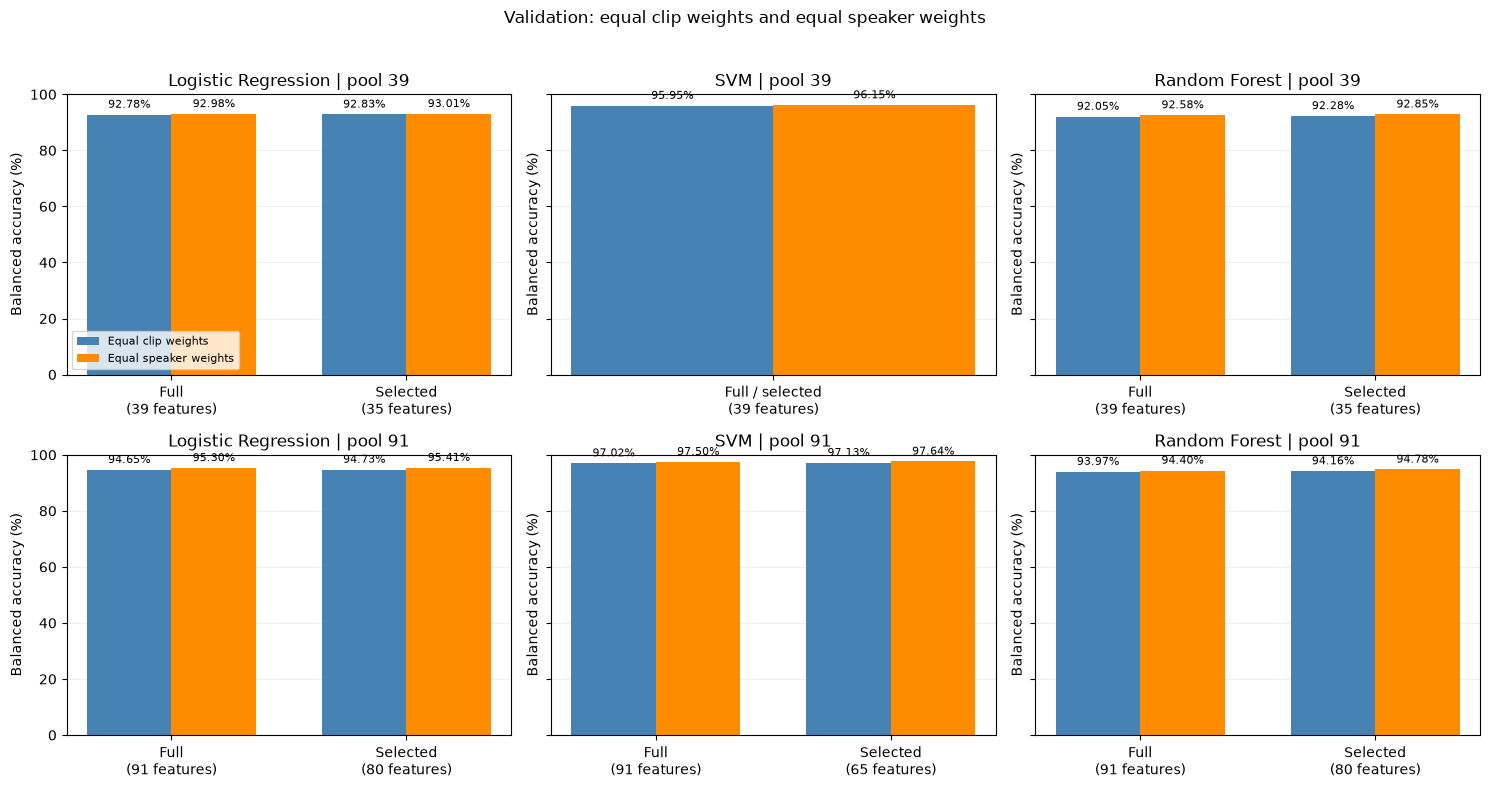

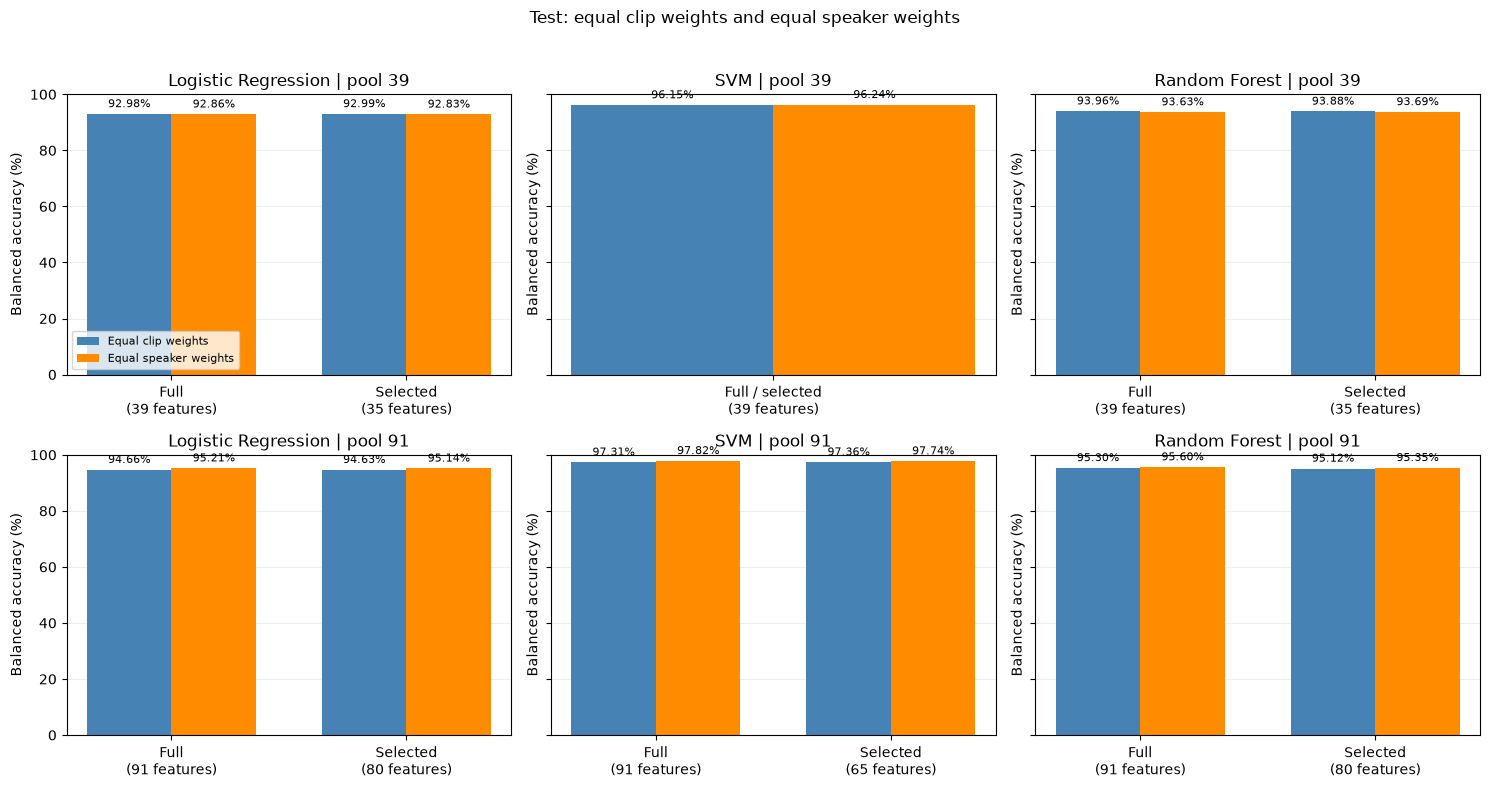

In [5]:
for split in SPLITS:
    fig, axes = plt.subplots(len(POOLS), len(MODEL_NAMES), figsize=(15, 8), sharey=True, squeeze=False)
    width = 0.36
    for row_axes, pool in zip(axes, POOLS):
        for axis, model in zip(row_axes, MODEL_NAMES):
            rows = comparison.loc[(comparison['feature_pool'] == pool)
                & (comparison['split'] == split) & (comparison['model'] == model)]
            positions = np.arange(len(rows))
            ordinary = axis.bar(positions - width / 2, rows['ordinary_balanced_accuracy_pct'],
                                width, label='Equal clip weights', color='steelblue')
            weighted = axis.bar(positions + width / 2, rows['speaker_weighted_balanced_accuracy_pct'],
                                width, label='Equal speaker weights', color='darkorange')
            axis.bar_label(ordinary, fmt='%.2f%%', padding=3, fontsize=8)
            axis.bar_label(weighted, fmt='%.2f%%', padding=3, fontsize=8)
            axis.set_xticks(positions, [f'{r.role}\n({r.feature_count} features)' for r in rows.itertuples()])
            axis.set(title=f'{MODEL_LABELS[model]} | pool {pool}', ylim=(0, 100),
                     ylabel='Balanced accuracy (%)')
            axis.grid(axis='y', alpha=0.2)
            axis.set_axisbelow(True)
    axes[0, 0].legend(fontsize=8, loc='lower left')
    fig.suptitle(f'{split.title()}: equal clip weights and equal speaker weights')
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

## 6. Read and save the comparison

Positive `clip_minus_speaker_points` means clip weighting scores higher.
Gain columns compare selected models with their full-feature baselines.
Speaker weights change scoring only; source effects and repeated clips remain.
Keep model and count choices fixed after testing.


In [6]:
for pool in POOLS:
    for split in SPLITS:
        rows = comparison.loc[(comparison['feature_pool'] == pool) & (comparison['split'] == split)]
        largest = rows.loc[rows['clip_minus_speaker_points'].abs().idxmax()]
        print(f"Pool {pool}, {split}: largest clip-minus-speaker difference is "
              f"{largest['clip_minus_speaker_points']:+.2f} percentage points "
              f"for {MODEL_LABELS[largest['model']]} ({largest['feature_count']} features).")
        for model in MODEL_NAMES:
            selected = rows.loc[(rows['model'] == model) & (rows['role'] == 'Selected')]
            if selected.empty:
                continue
            result = selected.iloc[0]
            print(f"  {MODEL_LABELS[model]}: selected-minus-full change is "
                  f"{result['ordinary_gain_from_full_points']:+.2f} points with clip weights and "
                  f"{result['speaker_weighted_gain_from_full_points']:+.2f} points with speaker weights.")

RESULTS_DIR = STUDY_DIR / 'speaker_weight_comparison'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
comparison.to_csv(RESULTS_DIR / 'score_comparison.csv', index=False)
speaker_summary.to_csv(RESULTS_DIR / 'speaker_summary.csv', index=False)
(RESULTS_DIR / 'comparison_sources.json').write_text(json.dumps({
    'dataset_id': identities['dataset_id'], 'audio_id': identities['audio_id'],
    'source_preprocessing': source_preprocessing,
    'source_sha256': {str(path.relative_to(PROJECT_ROOT)): value for path, value in source_hashes.items()},
    'clips': len(metadata),
    'class_counts': {str(label): int(count) for label, count in metadata['label'].value_counts().items()},
    'split_counts': metadata['split'].value_counts().to_dict(),
    'studies': {str(pool): {'cache_id': studies[pool]['cache_id'],
        'selected_counts': studies[pool]['selected_counts'],
        'test_prediction_source': run_rows[i]['test_prediction_source']}
        for i, pool in enumerate(POOLS)},
}, indent=2) + '\n')
for path, original_hash in source_hashes.items():
    if file_hash(path) != original_hash:
        raise ValueError(f'Original study input changed: {path}')
print('Original studies, caches and models are unchanged.')
print('Saved comparison:', RESULTS_DIR)

Pool 39, validation: largest clip-minus-speaker difference is -0.57 percentage points for Random Forest (35 features).
  Logistic Regression: selected-minus-full change is +0.05 points with clip weights and +0.03 points with speaker weights.
  Random Forest: selected-minus-full change is +0.23 points with clip weights and +0.27 points with speaker weights.
Pool 39, test: largest clip-minus-speaker difference is +0.33 percentage points for Random Forest (39 features).
  Logistic Regression: selected-minus-full change is +0.02 points with clip weights and -0.04 points with speaker weights.
  Random Forest: selected-minus-full change is -0.08 points with clip weights and +0.06 points with speaker weights.
Pool 91, validation: largest clip-minus-speaker difference is -0.67 percentage points for Logistic Regression (80 features).
  Logistic Regression: selected-minus-full change is +0.08 points with clip weights and +0.10 points with speaker weights.
  SVM: selected-minus-full change is +0.